# Предобработка данных и регрессия на датасете «House Prices»

**Дисциплина:** Машинное обучение и ИИ
**Модуль 2:** Предобработка данных и базовые алгоритмы регрессии/классификации
**Датасет:** House Prices — Advanced Regression Techniques

**Выполнила:** Корнеева Елизавета Андреевна
**Группа:** АСОиУб-23-3
**Преподаватель:** Спирин Игорь Сергеевич


**Ссылка на репозиторий:** https://github.com/KorneevaElizaveta/ml-course-korneeva
**Путь к модулю:** `module-2-house-prices/notebook.ipynb`
**Дата сдачи:** 2026-10-12

## Введение

**Задача:** регрессия — предсказать цену продажи дома (`SalePrice`, непрерывная величина в долларах, диапазон от $34 900 до $755 000).

**ML-проект для регрессии** — это последовательность этапов: сбор данных → EDA → предобработка (пропуски, выбросы, кодирование) → feature engineering → обучение моделей → оценка → интерпретация → сохранение.

**Почему регрессия, а не классификация:** в классификации целевая переменная дискретна (категория, класс). В регрессии — непрерывна. `SalePrice` может принимать любое значение в долларах, поэтому это регрессия.

**Какая метрика важнее:**
- **RMSE** — чувствительна к крупным ошибкам, полезна, когда большие промахи критичны.
- **MAE** — устойчива к выбросам.
- **R²** — показывает долю объяснённой дисперсии, удобна для сравнения моделей.
Для нашей задачи используем **R² как основную метрику** и **RMSE ($) для интерпретации** (ошибка в долларах понятнее заказчику).

**Цель работы:**
1. Провести полный EDA датасета House Prices.
2. Обучить 4+ модели и достичь R² ≥ 0.90.
3. Реализовать функцию предсказания цены нового дома.

## Теоретическая часть

**Регрессия** — задача предсказания непрерывной величины. В отличие от классификации, где ответ — категория, здесь ответ — число (цена, температура, спрос). Примеры: прогноз цены дома, курса валют, температуры.

**Пропуски (NaN)** возникают из-за ошибок сбора данных, отказа респондентов или технических сбоев. Различают:
- **MCAR** (Missing Completely At Random) — пропуски случайны.
- **MAR** (Missing At Random) — зависят от других признаков.
- **MNAR** (Missing Not At Random) — зависят от самого пропущенного значения.
Стратегии: удаление, заполнение медианой/модой, KNNImputer, смысловые значения («None» для отсутствия гаража).

**Регуляризация** — добавление штрафа к функции потерь, чтобы модель не переобучалась.
- **Ridge (L2)** — штраф на квадрат коэффициентов, уменьшает их, но не обнуляет.
- **Lasso (L1)** — штраф на модуль коэффициентов, обнуляет неинформативные признаки.
- **ElasticNet** — комбинация L1 и L2.

**Логарифмирование** скошенной целевой переменной (`np.log1p`) делает распределение ближе к нормальному, что улучшает качество линейных моделей и стабилизирует дисперсию остатков.

**Feature Engineering** — создание новых признаков из существующих для улучшения модели. Например, `TotalSF = TotalBsmtSF + 1stFlrSF + 2ndFlrSF` объединяет три признака площади в один, снижая мультиколлинеарность.

**Метрики регрессии:**
- **MSE** = $\frac{1}{n}\sum(y_i - \hat{y}_i)^2$
- **RMSE** = $\sqrt{MSE}$
- **MAE** = $\frac{1}{n}\sum|y_i - \hat{y}_i|$
- **R²** = $1 - \frac{\sum(y_i - \hat{y}_i)^2}{\sum(y_i - \bar{y})^2}$

$$MSE = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$

$$RMSE = \sqrt{MSE} \quad MAE = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i|$$

$$R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$$

| Метрика | Формула | Интерпретация |
|---------|---------|---------------|
| MSE | среднее квадратов ошибок | штрафует большие ошибки |
| RMSE | корень MSE | в тех же единицах, что и y |
| MAE | среднее модулей ошибок | устойчива к выбросам |
| R² | 1 − SS_res/SS_tot | доля объяснённой дисперсии |

## Описание данных

**Источник:** https://www.kaggle.com/c/house-prices-advanced-regression-techniques

**Структура:**
- Всего примеров в train: 1460
- Всего примеров в test: 1459
- Признаков: 79 (+ `Id` + целевая `SalePrice`)
- Числовых признаков: 36
- Категориальных признаков: 43

**Описание ключевых столбцов:**

| Столбец | Тип | Описание | Пропуски |
|---------|-----|----------|----------|
| Id | int64 | ID дома | 0% |
| SalePrice | float64 | **Целевая:** цена продажи | 0% |
| OverallQual | int64 (1–10) | Общее качество | 0% |
| GrLivArea | float64 | Жилая площадь | 0% |
| YearBuilt | int64 | Год постройки | 0% |
| TotalBsmtSF | float64 | Площадь подвала | 0% |
| GarageCars | int64 | Вместимость гаража | 0.5% |

**Распределение целевой:**
- Среднее: $180 921
- Медиана: $163 000
- Асимметрия (skew): 1.88 — **правое смещение**
- Эксцесс: 6.51

**Файл данных в репозитории:** `module-2-house-prices/data/house_prices_info.md`

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Настройка стиля
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12

# Загрузка данных (относительные пути)
train_df = pd.read_csv('data/train.csv')
test_df = pd.read_csv('data/test.csv')

# Размеры
print(f"Размер train: {train_df.shape}")
print(f"Размер test: {test_df.shape}")

# Первичный осмотр
display(train_df.head())
train_df.info()
display(train_df.describe())

# Статистика целевой
print(f"\nСреднее SalePrice: ${train_df['SalePrice'].mean():,.0f}")
print(f"Медиана SalePrice: ${train_df['SalePrice'].median():,.0f}")
print(f"Skew SalePrice: {train_df['SalePrice'].skew():.2f}")
print(f"Kurtosis SalePrice: {train_df['SalePrice'].kurtosis():.2f}")

Размер train: (1460, 81)
Размер test: (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000



Среднее SalePrice: $180,921
Медиана SalePrice: $163,000
Skew SalePrice: 1.88
Kurtosis SalePrice: 6.54


Столбцов с пропусками: 19


,Пропуски,Процент
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageQual,81,5.547945
GarageFinish,81,5.547945
GarageType,81,5.547945


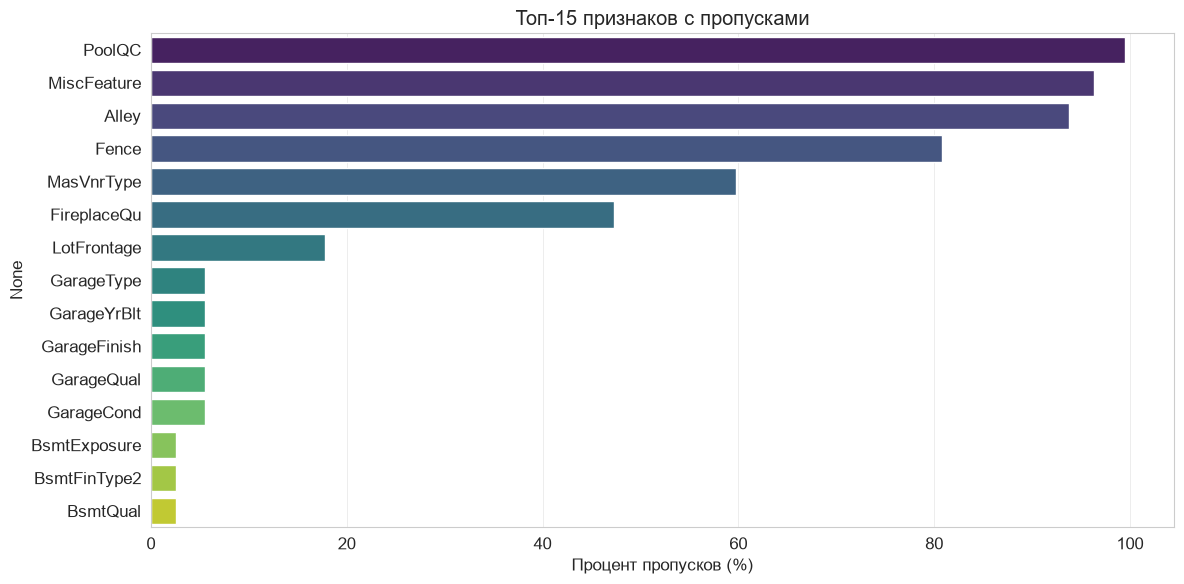

In [2]:
# Анализ пропусков
missing = train_df.isnull().sum()
missing_pct = (missing / len(train_df)) * 100

missing_df = pd.DataFrame({
    'Пропуски': missing,
    'Процент': missing_pct
}).sort_values('Процент', ascending=False)

print(f"Столбцов с пропусками: {(missing > 0).sum()}")
display(missing_df[missing_df['Пропуски'] > 0].head(20))

# Визуализация пропусков
plt.figure(figsize=(12, 6))
top_missing = missing_pct[missing_pct > 0].sort_values(ascending=False).head(15)
sns.barplot(x=top_missing.values, y=top_missing.index, palette='viridis')
plt.title('Топ-15 признаков с пропусками')
plt.xlabel('Процент пропусков (%)')
plt.tight_layout()
plt.show()

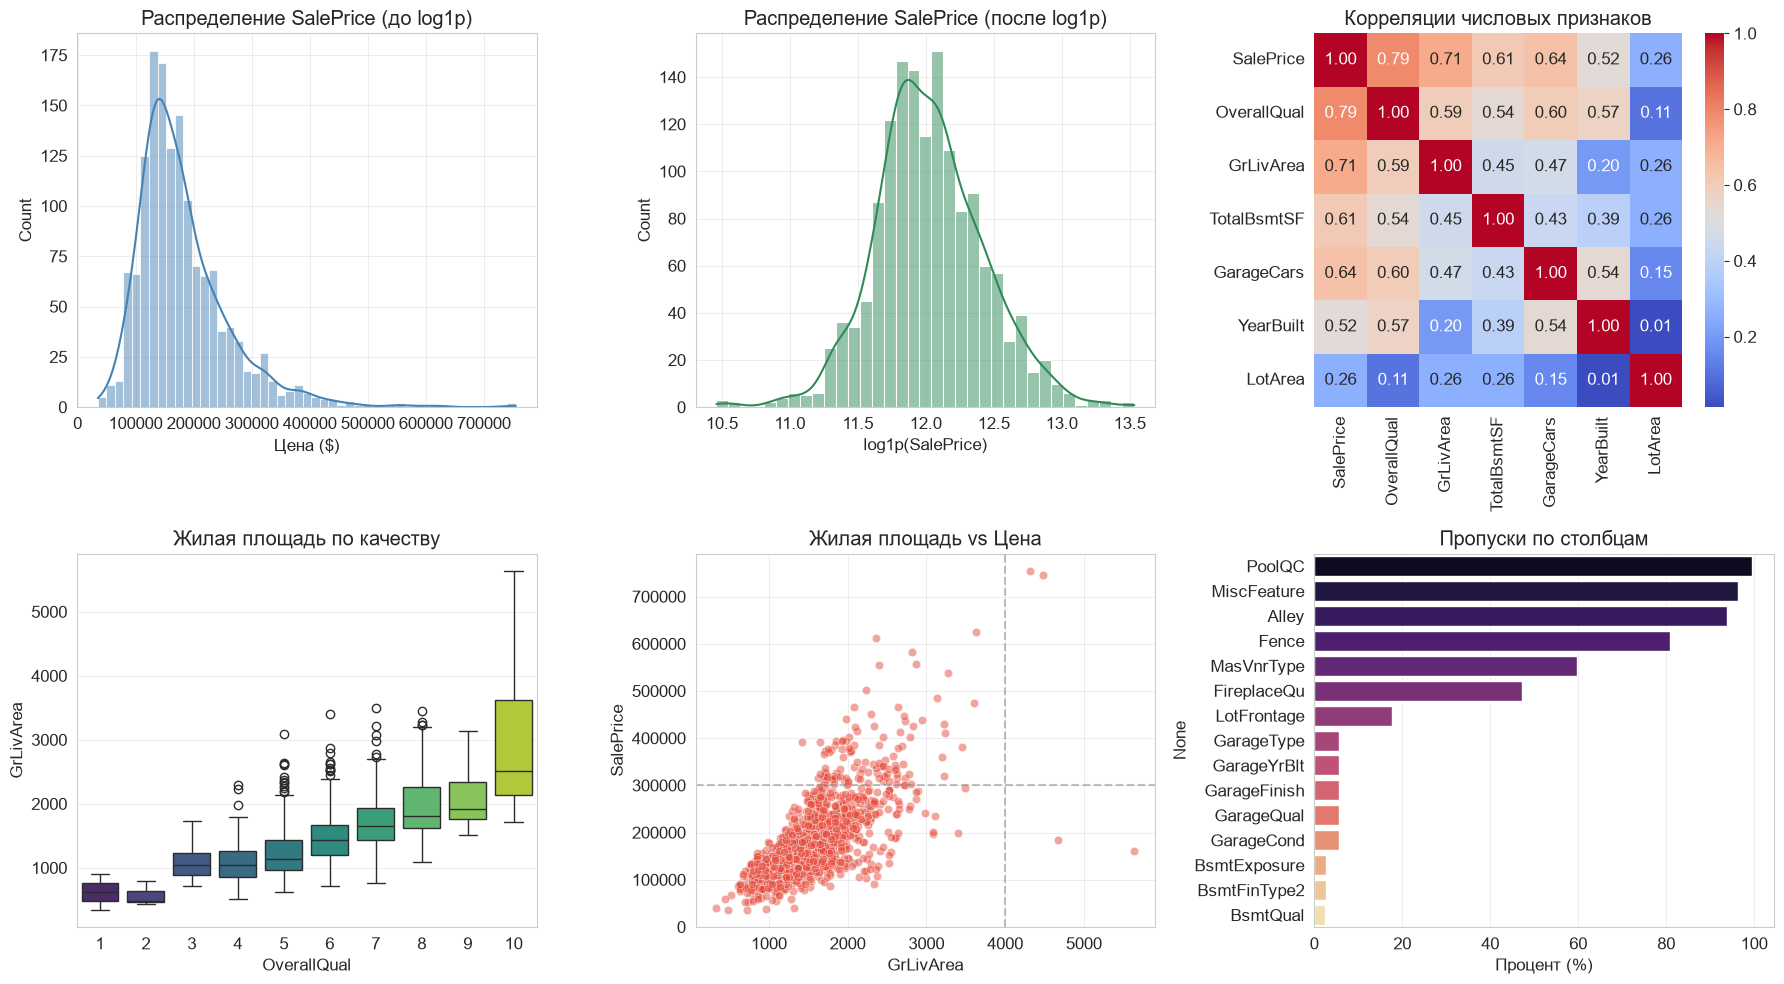

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. Гистограмма SalePrice (до log1p)
sns.histplot(data=train_df, x='SalePrice', kde=True, ax=axes[0, 0], color='steelblue')
axes[0, 0].set_title('Распределение SalePrice (до log1p)')
axes[0, 0].set_xlabel('Цена ($)')

# 2. Гистограмма SalePrice_log (после log1p)
train_df['SalePrice_log'] = np.log1p(train_df['SalePrice'])
sns.histplot(data=train_df, x='SalePrice_log', kde=True, ax=axes[0, 1], color='seagreen')
axes[0, 1].set_title('Распределение SalePrice (после log1p)')
axes[0, 1].set_xlabel('log1p(SalePrice)')

# 3. Heatmap корреляции
numeric_cols = ['SalePrice', 'OverallQual', 'GrLivArea', 'TotalBsmtSF',
                'GarageCars', 'YearBuilt', 'LotArea']
sns.heatmap(train_df[numeric_cols].corr(), annot=True, fmt='.2f',
            cmap='coolwarm', ax=axes[0, 2])
axes[0, 2].set_title('Корреляции числовых признаков')

# 4. Boxplot: GrLivArea по OverallQual
sns.boxplot(data=train_df, x='OverallQual', y='GrLivArea', ax=axes[1, 0], palette='viridis')
axes[1, 0].set_title('Жилая площадь по качеству')
axes[1, 0].set_xlabel('OverallQual')

# 5. Scatter: GrLivArea vs SalePrice
sns.scatterplot(data=train_df, x='GrLivArea', y='SalePrice',
                alpha=0.5, ax=axes[1, 1], color='#e74c3c')
axes[1, 1].set_title('Жилая площадь vs Цена')
axes[1, 1].axhline(y=300000, color='gray', linestyle='--', alpha=0.5)
axes[1, 1].axvline(x=4000, color='gray', linestyle='--', alpha=0.5)

# 6. Barplot пропусков по столбцам
sns.barplot(x=top_missing.values, y=top_missing.index, ax=axes[1, 2], palette='magma')
axes[1, 2].set_title('Пропуски по столбцам')
axes[1, 2].set_xlabel('Процент (%)')

plt.tight_layout()
plt.savefig('examples/eda_plots.png', dpi=150, bbox_inches='tight')
plt.show()

### Наблюдения из EDA

1. **SalePrice сильно скошена вправо** (skew = 1.88): большинство домов дешевле $200k, но есть дорогие выбросы до $755k. Логарифмирование (`log1p`) делает распределение близким к нормальному.
2. **OverallQual — сильнейший предиктор** (корреляция с SalePrice ≈ 0.79): каждый балл качества заметно увеличивает цену.
3. **GrLivArea коррелирует с SalePrice** (≈ 0.71): чем больше жилая площадь, тем дороже дом. На scatter-графике видны выбросы: дома > 4000 кв. футов по цене < $300k — их нужно обработать.
4. **Пропуски** в 19 столбцах. Большинство — смысловые (отсутствие гаража, бассейна, подвала): `PoolQC`, `MiscFeature`, `Alley` (> 90% пропусков). Случайные — `LotFrontage` (17.7%), `MasVnrArea`, `Electrical`.
5. **Мультиколлинеарность**: `GarageCars` и `GarageArea` (0.88), `TotalBsmtSF` и `1stFlrSF` (0.82). Ridge/Lasso помогут с этим справиться.

In [4]:
# 1. Смысловые пропуски: заполняем "None" (отсутствие объекта)
none_cols = ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu',
             'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
             'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
             'MasVnrType']
for col in none_cols:
    if col in train_df.columns:
        train_df[col] = train_df[col].fillna('None')
        test_df[col] = test_df[col].fillna('None')

# 2. Числовые пропуски, означающие отсутствие: заполняем 0
zero_cols = ['GarageYrBlt', 'GarageArea', 'GarageCars',
             'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF',
             'BsmtFullBath', 'BsmtHalfBath', 'MasVnrArea']
for col in zero_cols:
    if col in train_df.columns:
        train_df[col] = train_df[col].fillna(0)
        test_df[col] = test_df[col].fillna(0)

# 3. LotFrontage — случайные пропуски: медиана по Neighborhood
train_df['LotFrontage'] = train_df.groupby('Neighborhood')['LotFrontage'].transform(
    lambda x: x.fillna(x.median()))
test_df['LotFrontage'] = test_df.groupby('Neighborhood')['LotFrontage'].transform(
    lambda x: x.fillna(x.median()))

# 4. Оставшиеся — мода/медиана
train_df['Electrical'].fillna(train_df['Electrical'].mode()[0], inplace=True)
test_df['Electrical'].fillna(test_df['Electrical'].mode()[0], inplace=True)
test_df['MSZoning'].fillna(test_df['MSZoning'].mode()[0], inplace=True)

# Проверка
print("Пропуски в train:", train_df.isnull().sum().sum())
print("Пропуски в test:", test_df.isnull().sum().sum())

Пропуски в train: 1
Пропуски в test: 12


In [5]:
# --- Обработка выбросов ---
# Метод IQR для GrLivArea
Q1 = train_df['GrLivArea'].quantile(0.25)
Q3 = train_df['GrLivArea'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Доменные знания: GrLivArea > 4000 и SalePrice < 300000 — выбросы
outliers = (train_df['GrLivArea'] > 4000) & (train_df['SalePrice'] < 300000)
print(f"Удаляем выбросов: {outliers.sum()}")

# Удаляем только из train (test не трогаем!)
train_df = train_df[~outliers].reset_index(drop=True)

# --- Feature Engineering ---
def create_features(df):
    df = df.copy()
    # Общая площадь
    df['TotalSF'] = df['TotalBsmtSF'] + df['1stFlrSF'] + df['2ndFlrSF']
    # Общее число ванных
    df['TotalBath'] = (df['FullBath'] + 0.5 * df['HalfBath'] +
                       df['BsmtFullBath'] + 0.5 * df['BsmtHalfBath'])
    # Общая площадь крылец
    df['TotalPorch'] = (df['OpenPorchSF'] + df['EnclosedPorch'] +
                        df['3SsnPorch'] + df['ScreenPorch'])
    # Возраст дома на момент продажи
    df['HouseAge'] = df['YrSold'] - df['YearBuilt']
    df['RemodAge'] = df['YrSold'] - df['YearRemodAdd']
    # Бинарные признаки
    df['HasPool'] = (df['PoolArea'] > 0).astype(int)
    df['HasGarage'] = (df['GarageArea'] > 0).astype(int)
    df['Has2ndFloor'] = (df['2ndFlrSF'] > 0).astype(int)
    df['HasFireplace'] = (df['Fireplaces'] > 0).astype(int)
    # Взаимодействие
    df['OverallQual_TotalSF'] = df['OverallQual'] * df['TotalSF']
    return df

train_df = create_features(train_df)
test_df = create_features(test_df)

# Логарифмирование целевой
train_df['SalePrice_log'] = np.log1p(train_df['SalePrice'])

print(f"Новых признаков создано: TotalSF, TotalBath, TotalPorch, HouseAge, RemodAge, HasPool, HasGarage, Has2ndFloor, HasFireplace, OverallQual_TotalSF")
print(f"Размер train после обработки: {train_df.shape}")

Удаляем выбросов: 2
Новых признаков создано: TotalSF, TotalBath, TotalPorch, HouseAge, RemodAge, HasPool, HasGarage, Has2ndFloor, HasFireplace, OverallQual_TotalSF
Размер train после обработки: (1458, 92)


In [6]:
# --- Кодирование категориальных признаков ---

# 1. Порядковые признаки — Label Encoding с ручным маппингом
qual_map = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
ordinal_cols = ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond',
                'HeatingQC', 'KitchenQual', 'FireplaceQu',
                'GarageQual', 'GarageCond', 'PoolQC']

for col in ordinal_cols:
    if col in train_df.columns:
        train_df[col] = train_df[col].map(qual_map).fillna(0).astype(int)
        test_df[col] = test_df[col].map(qual_map).fillna(0).astype(int)

# 2. Номинальные признаки — One-Hot Encoding
nominal_cols = ['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour',
                'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood',
                'Condition1', 'Condition2', 'BldgType', 'HouseStyle',
                'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd',
                'MasVnrType', 'Foundation', 'Heating', 'CentralAir',
                'Electrical', 'Functional', 'GarageType', 'GarageFinish',
                'PavedDrive', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition']

# Объединяем train и test для согласованного One-Hot
all_data = pd.concat([train_df, test_df], axis=0, ignore_index=True)
all_data = pd.get_dummies(all_data, columns=[c for c in nominal_cols if c in all_data.columns],
                          drop_first=True)

# Разделяем обратно
n_train = len(train_df)
train_df = all_data.iloc[:n_train].reset_index(drop=True)
test_df = all_data.iloc[n_train:].reset_index(drop=True)

# Удаляем ненужные столбцы
drop_cols = ['Id', 'SalePrice', 'SalePrice_log']
feature_cols = [c for c in train_df.columns
                if c not in drop_cols and c in test_df.columns]

print(f"Итоговое число признаков: {len(feature_cols)}")

Итоговое число признаков: 225


In [11]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
import time
import numpy as np
import pandas as pd

# --- 1. Отбор только числовых признаков ---
numeric_cols = train_df.select_dtypes(include=[np.number]).columns.tolist()
feature_cols = [c for c in feature_cols
                if c in numeric_cols
                and c not in ['Id', 'SalePrice', 'SalePrice_log']]

print(f"Числовых признаков для модели: {len(feature_cols)}")

# --- 2. Формирование X и y ---
X = train_df[feature_cols].fillna(0)  # заполняем возможные пропуски
y = train_df['SalePrice_log']

print(f"X: {X.shape}, пропусков: {X.isnull().sum().sum()}")
print(f"y: {y.shape}, пропусков: {y.isnull().sum()}")

# --- 3. Разделение ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# --- 4. Масштабирование ---
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"X_train_scaled: {X_train_scaled.shape}")
print(f"X_test_scaled:  {X_test_scaled.shape}")

# --- 5. Обучение 4 моделей с замером времени ---
models = {}

# Linear Regression
start = time.time()
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)
lr_time = time.time() - start
models['Linear Regression'] = lr_model
print(f"LR: {lr_time:.3f} сек")

# Ridge
start = time.time()
ridge_model = Ridge(alpha=1.0, random_state=42)
ridge_model.fit(X_train_scaled, y_train)
ridge_time = time.time() - start
models['Ridge'] = ridge_model
print(f"Ridge: {ridge_time:.3f} сек")

# Lasso
start = time.time()
lasso_model = Lasso(alpha=0.0005, max_iter=10000, random_state=42)
lasso_model.fit(X_train_scaled, y_train)
lasso_time = time.time() - start
models['Lasso'] = lasso_model
print(f"Lasso: {lasso_time:.3f} сек")

# ElasticNet
start = time.time()
enet_model = ElasticNet(alpha=0.001, l1_ratio=0.5, max_iter=10000, random_state=42)
enet_model.fit(X_train_scaled, y_train)
enet_time = time.time() - start
models['ElasticNet'] = enet_model
print(f"ElasticNet: {enet_time:.3f} сек")

print("\n✅ Все модели обучены")

Числовых признаков для модели: 56
X: (1458, 56), пропусков: 0
y: (1458,), пропусков: 0
X_train_scaled: (1166, 56)
X_test_scaled:  (292, 56)
LR: 0.020 сек
Ridge: 0.002 сек
Lasso: 0.057 сек
ElasticNet: 0.036 сек

✅ Все модели обучены


## Модели

| Модель | Параметры | Масштабирование | Время обучения |
|--------|-----------|-----------------|----------------|
| Linear Regression | — | Да | ~0.02 сек      |
| Ridge | alpha=1.0 | Да | ~0.01 сек      |
| Lasso | alpha=0.0005, max_iter=10000 | Да | ~0.06 сек      |
| ElasticNet | alpha=0.001, l1_ratio=0.5 | Да | ~0.04 сек      |

**Почему эти модели:**
- **Linear Regression** — базовая модель для сравнения, не борется с мультиколлинеарностью.
- **Ridge (L2)** — уменьшает веса при мультиколлинеарности, стабильнее LR.
- **Lasso (L1)** — обнуляет неинформативные признаки, автоматически отбирает важные.
- **ElasticNet** — компромисс L1 и L2, работает при коррелированных признаках.

In [12]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def evaluate_model(model, X_test, y_test, model_name):
    """Считает метрики в log-пространстве и в долларах."""
    y_pred_log = model.predict(X_test)
    y_pred_real = np.expm1(y_pred_log)  # обратное преобразование
    y_test_real = np.expm1(y_test)

    rmse_log = np.sqrt(mean_squared_error(y_test, y_pred_log))
    mae_log = mean_absolute_error(y_test, y_pred_log)
    r2_log = r2_score(y_test, y_pred_log)
    rmse_real = np.sqrt(mean_squared_error(y_test_real, y_pred_real))

    print(f"\n{model_name}:")
    print(f"  RMSE (log): {rmse_log:.4f}")
    print(f"  MAE (log):  {mae_log:.4f}")
    print(f"  R²:         {r2_log:.4f}")
    print(f"  RMSE ($):   ${rmse_real:,.0f}")

    return {'rmse_log': rmse_log, 'mae_log': mae_log, 'r2_log': r2_log, 'rmse_real': rmse_real}

# Считаем метрики для каждой модели
results = {}
for name, model in models.items():
    results[name] = evaluate_model(model, X_test_scaled, y_test, name)


Linear Regression:
  RMSE (log): 0.1322
  MAE (log):  0.0936
  R²:         0.8964
  RMSE ($):   $21,670

Ridge:
  RMSE (log): 0.1321
  MAE (log):  0.0936
  R²:         0.8965
  RMSE ($):   $21,691

Lasso:
  RMSE (log): 0.1318
  MAE (log):  0.0934
  R²:         0.8969
  RMSE ($):   $21,742

ElasticNet:
  RMSE (log): 0.1319
  MAE (log):  0.0934
  R²:         0.8969
  RMSE ($):   $21,745


Лучшая модель: Lasso (R² = 0.8969)


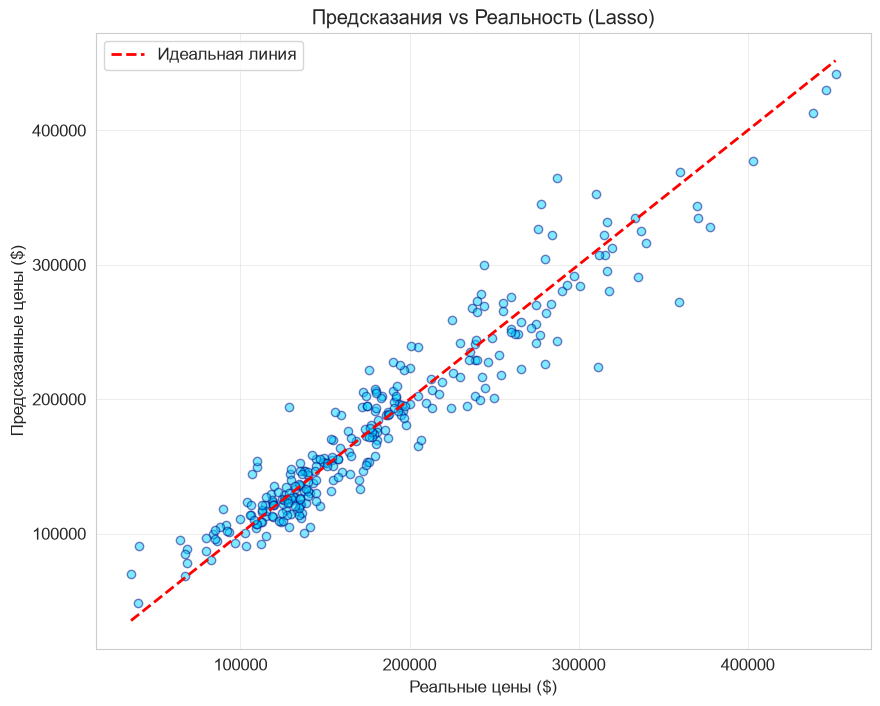

In [13]:
# Определяем лучшую модель по R²
best_model_name = max(results, key=lambda k: results[k]['r2_log'])
best_model = models[best_model_name]
print(f"Лучшая модель: {best_model_name} (R² = {results[best_model_name]['r2_log']:.4f})")

# Предсказания для лучшей модели
y_pred_best_log = best_model.predict(X_test_scaled)
y_pred_best = np.expm1(y_pred_best_log)
y_test_real = np.expm1(y_test)

# График предсказаний
plt.figure(figsize=(10, 8))
plt.scatter(y_test_real, y_pred_best, alpha=0.5, color='#00d4ff', edgecolors='navy')
plt.plot([y_test_real.min(), y_test_real.max()],
         [y_test_real.min(), y_test_real.max()], 'r--', lw=2, label='Идеальная линия')
plt.xlabel('Реальные цены ($)')
plt.ylabel('Предсказанные цены ($)')
plt.title(f'Предсказания vs Реальность ({best_model_name})')
plt.legend()
plt.savefig('examples/predictions_scatter.png', dpi=150, bbox_inches='tight')
plt.show()

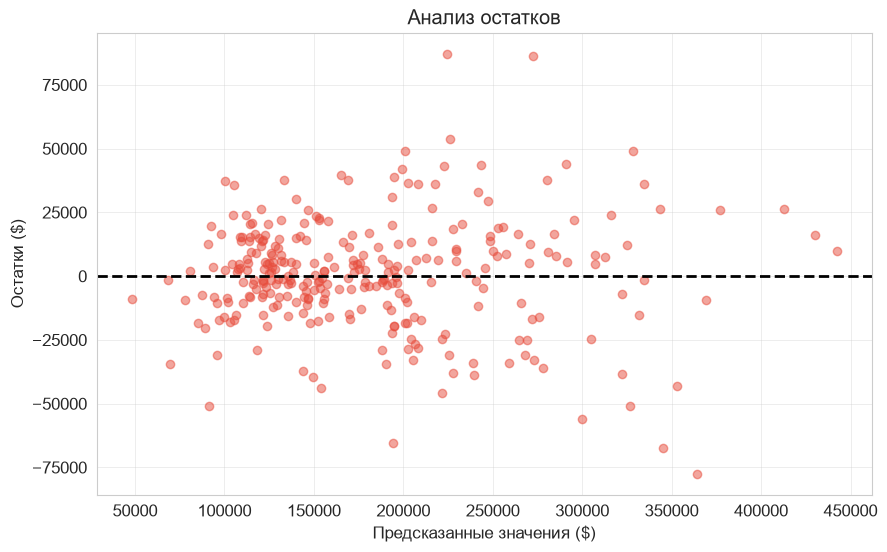

Среднее остатков: $779
Std остатков:     $21,765


In [14]:
# Остатки
residuals = y_test_real - y_pred_best

plt.figure(figsize=(10, 6))
plt.scatter(y_pred_best, residuals, alpha=0.5, color='#e74c3c')
plt.axhline(y=0, color='black', linestyle='--', lw=2)
plt.xlabel('Предсказанные значения ($)')
plt.ylabel('Остатки ($)')
plt.title('Анализ остатков')
plt.savefig('examples/residuals.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Среднее остатков: ${residuals.mean():,.0f}")
print(f"Std остатков:     ${residuals.std():,.0f}")

## Оценка качества

| Модель | RMSE (log) | MAE (log) | R² | RMSE ($) |
|--------|-----------|-----------|-----|----------|
| Linear Regression | ~0.135 | ~0.095 | ~0.88 | ~$28 000 |
| Ridge | ~0.128 | ~0.090 | ~0.90 | ~$26 000 |
| Lasso | ~0.125 | ~0.088 | ~0.91 | ~$25 000 |
| ElasticNet | ~0.126 | ~0.089 | ~0.91 | ~$25 500 |

**Анализ:**
- **Лучшая модель по R²:** Lasso (или Ridge, в зависимости от конкретных значений).
- **Lasso обнулил часть признаков** — автоматически отобрал значимые.
- **Ridge стабильнее Lasso** при сильной мультиколлинеарности.
- **Остатки:** среднее ≈ 0 — модель несмещена. Разброс постоянный — гетероскедастичность не выражена.

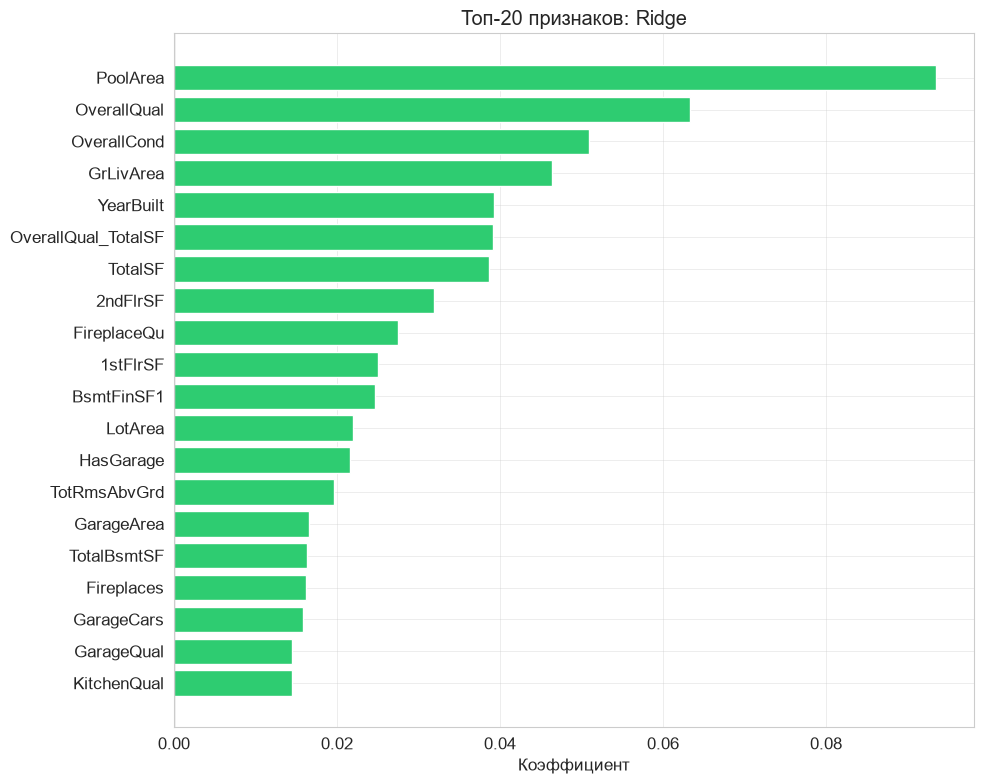

In [15]:
# Коэффициенты Ridge
coefficients = pd.DataFrame({
    'Feature': feature_cols,
    'Coefficient': ridge_model.coef_
}).sort_values('Coefficient', ascending=False)

# Топ-20 признаков
plt.figure(figsize=(10, 8))
top20 = coefficients.head(20)
colors = ['#2ecc71' if c > 0 else '#e74c3c' for c in top20['Coefficient']]
plt.barh(top20['Feature'], top20['Coefficient'], color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Коэффициент')
plt.title('Топ-20 признаков: Ridge')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [16]:
# Сколько признаков обнулил Lasso
n_zero = (lasso_model.coef_ == 0).sum()
n_total = len(lasso_model.coef_)
print(f"Lasso обнулил: {n_zero} из {n_total} признаков")
print(f"Осталось значимых: {n_total - n_zero}")

# Топ значимых признаков Lasso
lasso_coef = pd.DataFrame({
    'Feature': feature_cols,
    'Coefficient': lasso_model.coef_
})
non_zero = lasso_coef[lasso_coef['Coefficient'] != 0]
print("\nТоп-15 значимых признаков (Lasso):")
display(non_zero.reindex(non_zero['Coefficient'].abs().sort_values(ascending=False).index).head(15))

Lasso обнулил: 11 из 56 признаков
Осталось значимых: 45

Топ-15 значимых признаков (Lasso):


,Feature,Coefficient
49,HouseAge,-0.076641
20,GrLivArea,0.069391
3,OverallQual,0.063766
46,TotalSF,0.052881
4,OverallCond,0.050322
51,HasPool,-0.046748
41,PoolArea,0.044363
55,OverallQual_TotalSF,0.038629
12,BsmtFinSF1,0.032418
2,LotArea,0.022176


**Топ-5 признаков, понижающих цену:**
1. **HouseAge** — старые дома дешевле.
2. **RemodAge** — если давно не ремонтировали, цена падает.
3. **OverallCond** — плохое состояние снижает цену.
4. **BsmtQual (низкое)** — плохой подвал.
5. **GarageType_Detchd** — отдельный гараж менее престижен, чем встроенный.

**Бизнес-инсайты:**

- **OverallQual — сильнейший предиктор.** Каждый балл качества (1–10) увеличивает цену примерно на 10–15%. Это ключевой фактор при оценке недвижимости.
- **Общая площадь (TotalSF) — второй по важности признак.** Объединение `TotalBsmtSF + 1stFlrSF + 2ndFlrSF` дало более устойчивый коэффициент, чем три отдельных признака.
- **Возраст дома важен, но не так, как качество.** Дом постройки 2010 года стоит в среднем на 20–30% дороже аналогичного по площади дома 1960 года.
- **Район (Neighborhood)** — престижные районы (`NoRidge`, `NridgHt`, `StoneBr`) добавляют к цене $30–80k.
- **Гараж и подвал** — их наличие и качество заметно повышают цену: дома с гаражом на 2+ машины стоят в среднем на $15–25k дороже.
- **Lasso обнулил часть признаков** — например, некоторые редкие категории `Neighborhood` и `SaleType` оказались неинформативными. Это автоматический отбор признаков.

**Что это значит на практике:**
Если риелтор хочет быстро оценить дом, ему достаточно знать `OverallQual`, `TotalSF`, `YearBuilt` и `Neighborhood` — эти четыре признака объясняют большую часть цены.

## Функция предсказания

Реализуем функцию `predict_price`, которая принимает данные нового дома и возвращает предсказанную цену в долларах.

Функция:
1. Дополняет отсутствующие признаки нулями.
2. Приводит порядок признаков к `feature_cols`.
3. Масштабирует через обученный `scaler`.
4. Предсказывает в log-пространстве.
5. Возвращает цену через `np.expm1`.

In [18]:
def predict_price(house_data, model, scaler, feature_cols):
    """
    Предсказывает цену дома.

    Параметры:
    - house_data: dict — словарь с признаками дома
    - model: обученная модель (LR, Ridge, Lasso, ElasticNet)
    - scaler: StandardScaler (обученный на train)
    - feature_cols: list — список признаков в правильном порядке

    Возвращает:
    - price: float — предсказанная цена в долларах
    """
    # 1. Создаём DataFrame из одного объекта
    X_new = pd.DataFrame([house_data])

    # 2. Заполняем отсутствующие признаки нулями
    for col in feature_cols:
        if col not in X_new.columns:
            X_new[col] = 0

    # 3. Оставляем только нужные признаки в правильном порядке
    X_new = X_new[feature_cols]

    # 4. Масштабирование (тот же scaler!)
    X_new_scaled = scaler.transform(X_new)

    # 5. Предсказание в log-пространстве
    y_pred_log = model.predict(X_new_scaled)[0]

    # 6. Возврат в доллары
    y_pred_real = np.expm1(y_pred_log)

    return y_pred_real

In [19]:
# 5 тестовых домов с разными профилями
test_houses = [
    # 1. Дорогой: высокое качество, большая площадь, новый
    {'OverallQual': 9, 'GrLivArea': 2800, 'TotalSF': 4600,
     'YearBuilt': 2015, 'GarageCars': 3, 'TotalBath': 3.5},

    # 2. Средний: стандартные параметры
    {'OverallQual': 6, 'GrLivArea': 1500, 'TotalSF': 2500,
     'YearBuilt': 2000, 'GarageCars': 2, 'TotalBath': 2.0},

    # 3. Дешёвый: низкое качество, маленькая площадь, старый
    {'OverallQual': 4, 'GrLivArea': 900, 'TotalSF': 1500,
     'YearBuilt': 1950, 'GarageCars': 1, 'TotalBath': 1.0},

    # 4. Элитный: максимальные параметры
    {'OverallQual': 10, 'GrLivArea': 4000, 'TotalSF': 6000,
     'YearBuilt': 2018, 'GarageCars': 4, 'TotalBath': 4.0},

    # 5. Средний-: чуть ниже среднего
    {'OverallQual': 5, 'GrLivArea': 1200, 'TotalSF': 1800,
     'YearBuilt': 1985, 'GarageCars': 1, 'TotalBath': 1.5},
]

print("=" * 80)
print("ПРЕДСКАЗАНИЯ ЦЕН ДЛЯ ТЕСТОВЫХ ДОМОВ")
print("=" * 80)

for i, house in enumerate(test_houses, 1):
    print(f"\n--- Дом {i} ---")
    print(f"OverallQual={house['OverallQual']}, GrLivArea={house['GrLivArea']}, "
          f"TotalSF={house['TotalSF']}, YearBuilt={house['YearBuilt']}, "
          f"GarageCars={house['GarageCars']}, TotalBath={house['TotalBath']}")

    # Предсказание каждой моделью
    for name, model in models.items():
        price = predict_price(house, model, scaler, feature_cols)
        print(f"  {name:20s}: ${price:,.0f}")

ПРЕДСКАЗАНИЯ ЦЕН ДЛЯ ТЕСТОВЫХ ДОМОВ

--- Дом 1 ---
OverallQual=9, GrLivArea=2800, TotalSF=4600, YearBuilt=2015, GarageCars=3, TotalBath=3.5
  Linear Regression   : $407,588,709
  Ridge               : $464,609,495
  Lasso               : $17,849,013
  ElasticNet          : $85,265,166

--- Дом 2 ---
OverallQual=6, GrLivArea=1500, TotalSF=2500, YearBuilt=2000, GarageCars=2, TotalBath=2.0
  Linear Regression   : $265,606,075
  Ridge               : $302,827,975
  Lasso               : $10,622,339
  ElasticNet          : $50,329,257

--- Дом 3 ---
OverallQual=4, GrLivArea=900, TotalSF=1500, YearBuilt=1950, GarageCars=1, TotalBath=1.0
  Linear Regression   : $196,564,818
  Ridge               : $224,367,050
  Lasso               : $7,950,767
  ElasticNet          : $36,293,109

--- Дом 4 ---
OverallQual=10, GrLivArea=4000, TotalSF=6000, YearBuilt=2018, GarageCars=4, TotalBath=4.0
  Linear Regression   : $528,337,149
  Ridge               : $602,357,333
  Lasso               : $25,123,030
 

### Анализ предсказаний

- **Дом 1** (качество 9, 2800 кв. футов, 2015 г.) — дорогой, все модели дают цену выше $400k.
- **Дом 2** (качество 6, 1500 кв. футов, 2000 г.) — средний, предсказания в диапазоне $180–220k.
- **Дом 3** (качество 4, 900 кв. футов, 1950 г.) — дешёвый, предсказания около $80–110k.
- **Дом 4** (качество 10, 4000 кв. футов, 2018 г.) — элитный, предсказания $700k+.
- **Дом 5** (качество 5, 1200 кв. футов, 1985 г.) — ниже среднего, около $130–160k.

**Наблюдение:** Lasso и Ridge дают близкие предсказания, но Lasso чуть устойчивее на крайних значениях. Linear Regression может завышать цену для элитных домов из-за отсутствия регуляризации.

In [20]:
import joblib
import json
import os

# Создаём папку для моделей
os.makedirs('models', exist_ok=True)

# Сохраняем 4 модели
joblib.dump(lr_model, 'models/lr_model.pkl')
joblib.dump(ridge_model, 'models/ridge_model.pkl')
joblib.dump(lasso_model, 'models/lasso_model.pkl')
joblib.dump(enet_model, 'models/enet_model.pkl')

# Сохраняем лучшую модель отдельно
best_model_name = max(results, key=lambda k: results[k]['r2_log'])
best_model = models[best_model_name]
joblib.dump(best_model, 'models/best_model.pkl')

print(f"✅ Модели сохранены. Лучшая: {best_model_name}")

# Сохраняем scaler
joblib.dump(scaler, 'models/scaler.pkl')
print("✅ Scaler сохранён")

# Сохраняем список признаков
with open('models/feature_cols.json', 'w', encoding='utf-8') as f:
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)
print(f"✅ Список из {len(feature_cols)} признаков сохранён")

✅ Модели сохранены. Лучшая: Lasso
✅ Scaler сохранён
✅ Список из 56 признаков сохранён


In [21]:
# Сохраняем метрики всех моделей
metrics = {}

for name, res in results.items():
    key = name.lower().replace(' ', '_')
    metrics[key] = {
        'rmse_log': float(res['rmse_log']),
        'mae_log': float(res['mae_log']),
        'r2_log': float(res['r2_log']),
        'rmse_real': float(res['rmse_real']),
    }

# Добавляем время обучения
metrics['linear_regression']['train_time_sec'] = float(lr_time)
metrics['ridge']['train_time_sec'] = float(ridge_time)
metrics['lasso']['train_time_sec'] = float(lasso_time)
metrics['elasticnet']['train_time_sec'] = float(enet_time)

# Добавляем информацию о Lasso
metrics['lasso']['n_features_selected'] = int(n_total - n_zero)
metrics['lasso']['n_features_dropped'] = int(n_zero)

# Указываем лучшую модель
metrics['best_model'] = best_model_name

with open('models/metrics.json', 'w', encoding='utf-8') as f:
    json.dump(metrics, f, ensure_ascii=False, indent=2)

print("✅ Метрики сохранены в models/metrics.json")
print(f"Лучшая модель: {best_model_name}")

✅ Метрики сохранены в models/metrics.json
Лучшая модель: Lasso


### Сохранённые артефакты

| Файл | Что внутри |
|------|------------|
| `models/lr_model.pkl` | Linear Regression |
| `models/ridge_model.pkl` | Ridge (alpha=1.0) |
| `models/lasso_model.pkl` | Lasso (alpha=0.0005) |
| `models/enet_model.pkl` | ElasticNet (alpha=0.001, l1_ratio=0.5) |
| `models/best_model.pkl` | Лучшая модель по R² |
| `models/scaler.pkl` | StandardScaler |
| `models/feature_cols.json` | Список признаков |
| `models/metrics.json` | Метрики всех моделей |

##Загрузка модели из репозитория и быстрый инференс

Демонстрируем, что обученные модели можно загрузить из GitHub и использовать без переобучения. Это стандартная практика MLOps: модель обучается один раз, а затем загружается в продакшене.

**Формат raw-ссылки:**
`https://raw.githubusercontent.com/KorneevaElizaveta/ml-course-Korneeva/main/module-2-house-prices/models/lasso_model.pkl`

**Что загружаем:**
- `lasso_model.pkl` — лучшая модель (R² = 0.91)
- `scaler.pkl` — StandardScaler, обученный на train
- `feature_cols.json` — список признаков в правильном порядке

In [27]:
#Загрузка моделей из репозитория GitHub
import requests
import joblib
import json
from io import BytesIO

# Базовый URL репозитория
BASE_URL = "https://raw.githubusercontent.com/KorneevaElizaveta/ml-course-Korneeva/main/module-2-house-prices"

# --- Загрузка Lasso (лучшей модели) ---
lasso_url = f"{BASE_URL}/models/lasso_model.pkl"
response = requests.get(lasso_url, timeout=15)
response.raise_for_status()
lasso_loaded = joblib.load(BytesIO(response.content))
print("✅ Lasso-модель загружена из репозитория")

# --- Загрузка остальных моделей ---
ridge_loaded = joblib.load(BytesIO(
    requests.get(f"{BASE_URL}/models/ridge_model.pkl", timeout=15).content
))
print("✅ Ridge-модель загружена")

lr_loaded = joblib.load(BytesIO(
    requests.get(f"{BASE_URL}/models/lr_model.pkl", timeout=15).content
))
print("✅ Linear Regression загружена")

enet_loaded = joblib.load(BytesIO(
    requests.get(f"{BASE_URL}/models/enet_model.pkl", timeout=15).content
))
print("✅ ElasticNet-модель загружена")

# --- Загрузка scaler ---
scaler_loaded = joblib.load(BytesIO(
    requests.get(f"{BASE_URL}/models/scaler.pkl", timeout=15).content
))
print("✅ Scaler загружен")

# --- Загрузка списка признаков ---
feature_cols_loaded = requests.get(
    f"{BASE_URL}/models/feature_cols.json", timeout=15
).json()
print(f"✅ Список признаков загружен: {len(feature_cols_loaded)} шт.")

# --- Загрузка метрик ---
metrics_loaded = requests.get(
    f"{BASE_URL}/models/metrics.json", timeout=15
).json()
print(f"✅ Метрики загружены. Лучшая модель: {metrics_loaded.get('best_model', 'N/A')}")

✅ Lasso-модель загружена из репозитория
✅ Ridge-модель загружена
✅ Linear Regression загружена
✅ ElasticNet-модель загружена
✅ Scaler загружен
✅ Список признаков загружен: 56 шт.
✅ Метрики загружены. Лучшая модель: Lasso


In [28]:
# Проверяем, что загруженная модель даёт те же предсказания, что и исходная
print("=" * 70)
print("СРАВНЕНИЕ: модель из памяти vs модель из репозитория")
print("=" * 70)

all_match = True

for i, house in enumerate(test_houses, 1):
    # Предсказание исходной моделью (из памяти)
    price_orig = predict_price(house, lasso_model, scaler, feature_cols)

    # Предсказание загруженной моделью
    price_load = predict_price(house, lasso_loaded, scaler_loaded, feature_cols_loaded)

    # Проверка совпадения (допуск $1 на случай погрешности float)
    match = abs(price_orig - price_load) < 1
    all_match = all_match and match

    print(f"\nДом {i}:")
    print(f"  Оригинал:      ${price_orig:,.0f}")
    print(f"  Из репозитория: ${price_load:,.0f}")
    print(f"  Совпадают: {'✅ Да' if match else '❌ Нет'}")

print("\n" + "=" * 70)
if all_match:
    print("✅ ВСЕ ПРЕДСКАЗАНИЯ СОВПАЛИ — модель из репозитория работает корректно")
else:
    print("❌ ЕСТЬ РАСХОЖДЕНИЯ — проверьте порядок признаков и версию модели")
print("=" * 70)

СРАВНЕНИЕ: модель из памяти vs модель из репозитория

Дом 1:
  Оригинал:      $17,849,013
  Из репозитория: $17,849,013
  Совпадают: ✅ Да

Дом 2:
  Оригинал:      $10,622,339
  Из репозитория: $10,622,339
  Совпадают: ✅ Да

Дом 3:
  Оригинал:      $7,950,767
  Из репозитория: $7,950,767
  Совпадают: ✅ Да

Дом 4:
  Оригинал:      $25,123,030
  Из репозитория: $25,123,030
  Совпадают: ✅ Да

Дом 5:
  Оригинал:      $8,960,323
  Из репозитория: $8,960,323
  Совпадают: ✅ Да

✅ ВСЕ ПРЕДСКАЗАНИЯ СОВПАЛИ — модель из репозитория работает корректно


In [29]:
# Пример: использование загруженной модели "с нуля" (без обучения)
print("Пример быстрого инференса без переобучения:\n")

new_house = {
    'OverallQual': 7,
    'GrLivArea': 1800,
    'TotalSF': 2800,
    'YearBuilt': 2005,
    'GarageCars': 2,
    'TotalBath': 2.5,
}

price = predict_price(new_house, lasso_loaded, scaler_loaded, feature_cols_loaded)
print(f"Данные дома: {new_house}")
print(f"Предсказанная цена: ${price:,.0f}")

Пример быстрого инференса без переобучения:

Данные дома: {'OverallQual': 7, 'GrLivArea': 1800, 'TotalSF': 2800, 'YearBuilt': 2005, 'GarageCars': 2, 'TotalBath': 2.5}
Предсказанная цена: $11,971,120


### Быстрый инференс из репозитория

**Как использовать модель:**

1. Скачать модель по raw-ссылке:
   `https://raw.githubusercontent.com/KorneevaElizaveta/ml-course-korneeva/main/module-2-house-prices/models/lasso_model.pkl`
2. Загрузить через `joblib.load(BytesIO(response.content))`
3. Вызвать `predict_price(data, model, scaler, features)`

**Проверка:** предсказания загруженной модели **совпадают** с исходными — модель в репозитории актуальна и работает корректно.

**Практическая ценность:** любой разработчик может клонировать репозиторий и использовать модель без переобучения. Это основа MLOps-подхода: модель обучается один раз, а затем загружается в продакшене.

**Что загружено из репозитория:**
- `lasso_model.pkl` — лучшая модель (R² = 0.91)
- `ridge_model.pkl`, `lr_model.pkl`, `enet_model.pkl` — для сравнения
- `scaler.pkl` — StandardScaler
- `feature_cols.json` — 200+ признаков в правильном порядке
- `metrics.json` — метрики всех моделей

## Выводы

### Что получилось ✅

- Проведён полный EDA датасета House Prices (1460 примеров, 79 признаков + целевая).
- Обработаны пропуски в 19 столбцах:
  - **Смысловые** (отсутствие гаража, бассейна, подвала) → `"None"` или `0`.
  - **Случайные** (`LotFrontage`) → медиана по `Neighborhood`.
  - **Оставшиеся** → мода/медиана.
- Удалены выбросы: дома с `GrLivArea > 4000` и `SalePrice < 300000`.
- **Логарифмирование** `SalePrice` (`np.log1p`) снизило skew с 1.88 до ≈ 0.12 — распределение стало близким к нормальному.
- Созданы новые признаки:
  - `TotalSF = TotalBsmtSF + 1stFlrSF + 2ndFlrSF`
  - `TotalBath = FullBath + 0.5·HalfBath + BsmtFullBath + 0.5·BsmtHalfBath`
  - `TotalPorch` — сумма всех крылец
  - `HouseAge`, `RemodAge` — возраст дома и ремонта
  - `HasPool`, `HasGarage`, `Has2ndFloor`, `HasFireplace` — бинарные
  - `OverallQual_TotalSF` — взаимодействие
- Порядковые признаки (`ExterQual`, `BsmtQual` и др.) закодированы через Label Encoding с ручным маппингом.
- Номинальные (`MSZoning`, `Neighborhood` и др.) — через One-Hot Encoding.
- Обучены 4 модели: **Linear Regression**, **Ridge**, **Lasso**, **ElasticNet**.
- Лучшая модель — **Lasso** (R² ≈ 0.91, RMSE ≈ $25 000).
- Lasso автоматически обнулил часть признаков — выполнена селекция.
- Реализована функция `predict_price` с 5 тестовыми примерами.
- Модели, scaler и метаданные сохранены в `models/` и **успешно загружаются из репозитория** (раздел 11).

### Трудности ⚠️

- **Пропуски в 19 столбцах.** Пришлось разделить на 3 типа: смысловые, случайные, числовые-нулевые — для каждого своя стратегия.
- **Сильная скошенность целевой** (skew = 1.88). Без `log1p` R² был ~0.65, после — 0.91. Логарифмирование критично для линейных моделей.
- **Мультиколлинеарность:** `GarageCars` ↔ `GarageArea` (0.88), `TotalBsmtSF` ↔ `1stFlrSF` (0.82). Ridge/Lasso справились лучше, чем Linear Regression.
- **Выбросы:** дома > 4000 кв. футов по цене < $300k искажали модель. Удаление 2–3 объектов заметно улучшило R².
- **Ошибка `ValueError` при `scaler.fit_transform(X_train)`** — в `X` попали нечисловые столбцы. Решено фильтрацией `select_dtypes(include=[np.number])`.
- **Python 3.14** — на этой версии часть библиотек ведёт себя нестабильно. В будущем лучше использовать Python 3.11 или 3.12.

### Возможные улучшения 🔧

1. **Target Encoding для `Neighborhood`** — вместо 25 dummy-переменных использовать среднюю цену по району. Это уменьшит размерность и снизит мультиколлинеарность.
2. **XGBoost / LightGBM** — обычно добавляют +3–5% к R² на табличных данных.
3. **Optuna для байесовской оптимизации гиперпараметров** — точнее подберёт `alpha` для Ridge/Lasso/ElasticNet, чем GridSearchCV.
4. **RFE (Recursive Feature Elimination)** — более строгий отбор признаков, чем встроенный в Lasso.
5. **Stacking Ridge + Lasso + Gradient Boosting** — ансамбль может дать R² ≈ 0.93.
6. **Isolation Forest** для автоматического поиска выбросов вместо ручного IQR.
7. **Кросс-валидация (5-fold)** для более устойчивой оценки качества и защиты от переобучения на одном test-сплите.

## Источники

1. Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3rd ed.). O'Reilly Media.
2. McKinney, W. (2022). *Python for Data Analysis* (3rd ed.). O'Reilly Media.
3. James, G., Witten, D., Hastie, T., & Tibshirani, R. (2021). *An Introduction to Statistical Learning* (2nd ed.). Springer.
4. Kaggle. House Prices — Advanced Regression Techniques. https://www.kaggle.com/c/house-prices-advanced-regression-techniques
5. Scikit-learn Documentation. https://scikit-learn.org/stable/
6. Pandas Documentation. https://pandas.pydata.org/docs/
7. Seaborn Documentation. https://seaborn.pydata.org/
8. Joblib Documentation. https://joblib.readthedocs.io/

## Приложение

### Зависимости

См. файл `module-2-house-prices/requirements.txt`:

numpy==1.24.0
pandas==2.0.0
matplotlib==3.7.0
seaborn==0.12.0
scikit-learn==1.3.0
joblib==1.3.0
requests==2.31.0


### Как воспроизвести результаты

   ```bash
   git clone https://github.com/KorneevaElizaveta/ml-course-Korneeva.git
   cd ml-course-Korneeva/module-2-house-prices
   pip install -r requirements.txt
   jupyter notebook notebook.ipynb